# Практика 2. MLflow: журнал экспериментов и реестр моделей

**Перед началом:** этот файл только для чтения и общий для всей группы.
Сохраните свою копию: **File → Save Notebook As…** → `work/students/<ваше_имя>/02_mlflow.ipynb`.

Веб-интерфейс MLflow: **http://10.162.1.86:5000** — войдите своим логином, держите вкладку открытой
и смотрите, как после каждой ячейки там появляются запуски.

План:
1. Установка
2. Подключение со своим логином
3. **Первые шаги: от простого к сложному** — один запуск, несколько подряд, ветвление на два параллельных
4. Главные понятия
5. Эксперимент на настоящих данных
6. Артефакты: графики, отчёты, файлы
7. Сохранение и загрузка модели
8. Перебор параметров и поиск лучшего запуска
9. Метрики по эпохам (как в deep learning)
10. Реестр моделей: версии и метка `champion`
11. Автологирование
12. **Задачи**

## 1. Установка

- **mlflow-skinny** — лёгкий клиент MLflow (без веб-сервера: сервер у нас уже запущен). Версия клиента должна
  совпадать с версией сервера — у нас **3.16.1**.
- **skops** — безопасный формат сохранения моделей sklearn, его использует MLflow 3.

На сервере всё установлено, команда только проверит.

In [3]:
%pip install -q "mlflow-skinny==3.16.1" skops scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import mlflow
print("mlflow", mlflow.__version__)

mlflow 3.16.1


## 2. Подключение

| Что | Значение |
|---|---|
| адрес сервера (`MLFLOW_TRACKING_URI`) | внутри сервера `http://mlflow:5000`, снаружи `http://10.162.1.86:5000` |
| логин (`MLFLOW_TRACKING_USERNAME`) | ваш логин: `user1` … `user30` |
| пароль (`MLFLOW_TRACKING_PASSWORD`) | выдаёт преподаватель |

MLflow берёт адрес, логин и пароль **из переменных окружения** — так устроен клиент MLflow:

| Переменная | Что в ней |
|---|---|
| `MLFLOW_TRACKING_URI` | адрес сервера MLflow |
| `MLFLOW_TRACKING_USERNAME` | логин |
| `MLFLOW_TRACKING_PASSWORD` | пароль |

Пароль вводим через `getpass` — в коде его нет.

> Работаете **на своём компьютере** (VS Code, Anaconda)? Адрес `http://mlflow:5000` там не работает —
> это внутреннее имя сервера. Ячейка ниже сама возьмёт внешний адрес `http://10.162.1.86:5000`.

**Права:** вы видите эксперименты всей группы, но менять можете только **свои**.
Поэтому все имена начинаем со своего логина: `user7_wine`, `user7_wine_model`.

In [ ]:
import os

MLFLOW_USER = "user1"
UI = "http://localhost:5000"

# Локальный сервер запущен без авторизации.
# Убираем настройки авторизации, если они остались в окружении.
for variable in (
    "MLFLOW_TRACKING_USERNAME",
    "MLFLOW_TRACKING_PASSWORD",
    "MLFLOW_TRACKING_TOKEN",
):
    os.environ.pop(variable, None)

os.environ["MLFLOW_TRACKING_URI"] = UI
mlflow.set_tracking_uri(UI)
os.environ["MLFLOW_ENABLE_PROXY_MULTIPART_DOWNLOAD"] = "false"

print("Сервер MLflow:", mlflow.get_tracking_uri())
print("Префикс для имён экспериментов:", MLFLOW_USER)

Сервер MLflow: http://localhost:5000
Префикс для имён экспериментов: user1


In [6]:
# проверка связи: 5 последних экспериментов на сервере
for e in mlflow.search_experiments(max_results=5, order_by=["last_update_time DESC"]):
    print(e.experiment_id, e.name)

2 user1_wine
1 user1_first_steps
0 Default


## 3. Первые шаги: от простого к сложному

Прежде чем обучать модели, посмотрим, как MLflow записывает запуски, на самых простых примерах.
Держите открытой вкладку **http://10.162.1.86:5000** и после каждой ячейки обновляйте страницу.

### 3.1 Один запуск
Минимум, который нужен MLflow: **эксперимент** (папка) и **запуск** внутри него.

In [7]:
mlflow.set_experiment(f"{MLFLOW_USER}_first_steps")       # папка для запусков (создастся сама)

with mlflow.start_run(run_name="step1_hello"):             # один запуск
    mlflow.log_param("learning_rate", 0.1)                 # параметр: с чем запускали
    mlflow.log_metric("accuracy", 0.85)                    # метрика: что получилось

print("готово — в интерфейсе появился эксперимент", f"{MLFLOW_USER}_first_steps", "и в нём 1 запуск")

🏃 View run step1_hello at: http://localhost:5000/#/experiments/1/runs/d9bc4abde0f94abaa9e3d58c157663f7
🧪 View experiment at: http://localhost:5000/#/experiments/1
готово — в интерфейсе появился эксперимент user1_first_steps и в нём 1 запуск


### 3.2 Несколько запусков подряд
Каждая итерация цикла — **отдельный запуск**. Так делают, когда перебирают параметры:
в интерфейсе запуски встанут строками таблицы, и их можно сравнить.

In [8]:
for lr in [0.001, 0.01, 0.1]:
    with mlflow.start_run(run_name=f"step2_lr_{lr}"):
        mlflow.log_param("learning_rate", lr)
        mlflow.log_metric("accuracy", round(0.7 + lr, 3))  # «результат» — пока просто число
        print("запуск с learning_rate =", lr)

runs = mlflow.search_runs(experiment_names=[f"{MLFLOW_USER}_first_steps"], order_by=["start_time ASC"])
runs[["tags.mlflow.runName", "params.learning_rate", "metrics.accuracy"]]

запуск с learning_rate = 0.001
🏃 View run step2_lr_0.001 at: http://localhost:5000/#/experiments/1/runs/ced0523c40394d2bb98b15702fcb7ef9
🧪 View experiment at: http://localhost:5000/#/experiments/1
запуск с learning_rate = 0.01
🏃 View run step2_lr_0.01 at: http://localhost:5000/#/experiments/1/runs/49a9e2ddc3bd4402bac163cbf89b56c9
🧪 View experiment at: http://localhost:5000/#/experiments/1
запуск с learning_rate = 0.1
🏃 View run step2_lr_0.1 at: http://localhost:5000/#/experiments/1/runs/d0f9474014d6421f83fb3dc33daf2a69
🧪 View experiment at: http://localhost:5000/#/experiments/1


,tags.mlflow.runName,params.learning_rate,metrics.accuracy
0,step1_hello,0.1,0.850
1,step2_lr_0.001,0.001,0.701
2,step2_lr_0.01,0.01,0.710
3,step2_lr_0.1,0.1,0.800
4,step3_pipeline,NaN,NaN
5,logreg,NaN,NaN
6,decision_tree,NaN,NaN
7,step4_parallel,NaN,NaN
8,decision_tree,NaN,NaN
9,logreg,NaN,NaN


### 3.3 Один запуск разветвляется на два
Часто один шаг готовит данные, а дальше из них обучают **несколько моделей**.
В MLflow это **родительский запуск** с **дочерними** (`nested=True`):

```
pipeline (родитель: данные)
 ├── logreg          (дочерний)
 └── decision_tree   (дочерний)
```
В интерфейсе дочерние запуски спрятаны под родителем — нажмите «+» слева от `pipeline`.

In [9]:
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score

X, y = load_wine(return_X_y=True, as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

with mlflow.start_run(run_name="step3_pipeline"):                          # РОДИТЕЛЬ: данные
    mlflow.log_params({"dataset": "wine", "train_rows": len(X_train), "test_rows": len(X_test)})

    with mlflow.start_run(run_name="logreg", nested=True):                 # ребёнок 1
        m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)).fit(X_train, y_train)
        mlflow.log_metric("f1_macro", f1_score(y_test, m.predict(X_test), average="macro"))

    with mlflow.start_run(run_name="decision_tree", nested=True):          # ребёнок 2
        m = DecisionTreeClassifier(max_depth=2, random_state=42).fit(X_train, y_train)
        mlflow.log_metric("f1_macro", f1_score(y_test, m.predict(X_test), average="macro"))

print("родитель и 2 дочерних запуска записаны")

🏃 View run logreg at: http://localhost:5000/#/experiments/1/runs/c3755da47ade408d852a94ed63c76ff5
🧪 View experiment at: http://localhost:5000/#/experiments/1
🏃 View run decision_tree at: http://localhost:5000/#/experiments/1/runs/9466415504c8446c91cb5cc68bb2ee35
🧪 View experiment at: http://localhost:5000/#/experiments/1
🏃 View run step3_pipeline at: http://localhost:5000/#/experiments/1/runs/123f6cd9e129439b9a19a5e8ebf6ac85
🧪 View experiment at: http://localhost:5000/#/experiments/1
родитель и 2 дочерних запуска записаны


### 3.4 Два дочерних запуска параллельно, результат — обратно в родителя
В 3.3 модели обучались **по очереди**. Если модели обучаются долго (нейросети — часами),
их запускают **одновременно**. После этого родитель собирает результаты и записывает лучшую модель:

```
                ┌──► logreg          ─┐
step4_pipeline ─┤                     ├──► лучшая модель → в родителя
                └──► decision_tree   ─┘
```
Каждый поток открывает свой дочерний запуск и явно указывает родителя (`parent_run_id`).

In [10]:
import time
from concurrent.futures import ThreadPoolExecutor

def train_child(name, model, parent_id):
    """Обучает одну модель в своём дочернем запуске. Возвращает (имя, f1, время старта, время конца)."""
    with mlflow.start_run(run_name=name, parent_run_id=parent_id, nested=True):
        start = time.time()
        model.fit(X_train, y_train)
        time.sleep(2)                                       # имитация долгого обучения
        f1 = f1_score(y_test, model.predict(X_test), average="macro")
        mlflow.log_metric("f1_macro", f1)
        return name, f1, start, time.time()

models = {
    "logreg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
    "decision_tree": DecisionTreeClassifier(max_depth=2, random_state=42),
}

with mlflow.start_run(run_name="step4_parallel") as parent:
    mlflow.log_param("dataset", "wine")
    t0 = time.time()
    with ThreadPoolExecutor(max_workers=2) as pool:                        # два потока одновременно
        results = list(pool.map(lambda item: train_child(*item, parent.info.run_id), models.items()))

    best_name, best_f1, _, _ = max(results, key=lambda r: r[1])           # сбор результатов
    mlflow.log_params({"best_model": best_name})
    mlflow.log_metric("best_f1", best_f1)

for name, f1, start, end in results:
    print(f"{name:<14} f1={f1:.3f}   обучение с {start - t0:.1f} по {end - t0:.1f} с")
parallel = max(r[3] for r in results) - min(r[2] for r in results)     # от первого старта до последнего конца
one_by_one = sum(r[3] - r[2] for r in results)                          # если бы обучали по очереди
print(f"обучение заняло {parallel:.1f} с, по очереди было бы {one_by_one:.1f} с | лучшая: {best_name}")

🏃 View run logreg at: http://localhost:5000/#/experiments/1/runs/d3fae034d8bc4040a23207b6ff6eb1e5
🧪 View experiment at: http://localhost:5000/#/experiments/1
🏃 View run decision_tree at: http://localhost:5000/#/experiments/1/runs/15d14c7e2ba8406389a27b67d405f18c
🧪 View experiment at: http://localhost:5000/#/experiments/1
🏃 View run step4_parallel at: http://localhost:5000/#/experiments/1/runs/2570ada9c6ef4989bd87c3b61bf2c9be
🧪 View experiment at: http://localhost:5000/#/experiments/1
logreg         f1=1.000   обучение с 0.2 по 2.2 с
decision_tree  f1=0.879   обучение с 0.2 по 2.3 с
обучение заняло 2.1 с, по очереди было бы 4.1 с | лучшая: logreg


Посмотрите: обе модели начали и закончили **в одно время** — они шли параллельно.
Это та же схема, по которой в Airflow одна задача раздаёт работу нескольким параллельным задачам,
а следующая задача собирает результаты. Дальше разберём всё подробно на настоящих моделях.

## 4. Главные понятия

| Понятие | Что это | Пример |
|---|---|---|
| **Experiment** | папка для запусков одной задачи | `user7_wine` |
| **Run** | один запуск обучения | «логрегрессия, C=1» |
| **Params** | с чем обучали (входы) | `C=1.0`, `max_iter=5000` |
| **Metrics** | что получилось (числа, можно по шагам) | `accuracy=0.97` |
| **Tags** | подписи для поиска | `model_type=logreg` |
| **Artifacts** | файлы запуска | график, отчёт, модель |
| **Registered model** | модель в реестре с версиями | `user7_wine_model` v1, v2… |
| **Alias** | метка версии | `@champion` — основная |

## 5. Эксперимент на настоящих данных

`set_experiment` выбирает эксперимент (и создаёт, если его нет). Всё, что внутри `with mlflow.start_run():`,
попадает в один запуск.

> После каждого запуска MLflow сам печатает строку `🏃 View run … at: http://mlflow:5000/…`.
> `mlflow` — внутреннее имя сервера, из браузера оно не откроется. Открывайте ссылки, которые печатаем мы
> (с адресом `http://10.162.1.86:5000`), или замените в ссылке `mlflow` на `10.162.1.86`.

In [11]:
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score

X, y = load_wine(return_X_y=True, as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

EXPERIMENT = f"{MLFLOW_USER}_wine"
exp = mlflow.set_experiment(EXPERIMENT)
print("эксперимент:", exp.name, "id =", exp.experiment_id)

эксперимент: user1_wine id = 2


In [12]:
params = {"C": 1.0, "max_iter": 5000}

with mlflow.start_run(run_name="logreg_C1") as run:
    mlflow.log_params(params)                                   # 1) с чем обучали
    mlflow.set_tag("model_type", "logreg")                      # 2) подпись для поиска

    model = make_pipeline(StandardScaler(), LogisticRegression(**params)).fit(X_train, y_train)
    pred = model.predict(X_test)

    mlflow.log_metrics({                                        # 3) что получилось
        "accuracy": accuracy_score(y_test, pred),
        "f1_macro": f1_score(y_test, pred, average="macro"),
    })

print("run id:", run.info.run_id)
print("открыть в браузере:", f"{UI}/#/experiments/{exp.experiment_id}/runs/{run.info.run_id}")

🏃 View run logreg_C1 at: http://localhost:5000/#/experiments/2/runs/6bac92a0c0e4479d97f5c5b97f5db1e9
🧪 View experiment at: http://localhost:5000/#/experiments/2
run id: 6bac92a0c0e4479d97f5c5b97f5db1e9
открыть в браузере: http://localhost:5000/#/experiments/2/runs/6bac92a0c0e4479d97f5c5b97f5db1e9


## 6. Артефакты

Артефакт — любой файл запуска. Файлы MLflow сам кладёт в S3 (бакет `mlflow`), вам ключи S3 не нужны.

| Команда | Что сохраняет |
|---|---|
| `mlflow.log_figure(fig, "cm.png")` | график matplotlib |
| `mlflow.log_dict(d, "report.json")` | словарь как JSON |
| `mlflow.log_text(s, "notes.txt")` | строку как текстовый файл |
| `mlflow.log_artifact("путь")` | любой файл с диска |

In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

with mlflow.start_run(run_name="logreg_with_artifacts") as run:
    mlflow.log_params(params)
    model = make_pipeline(StandardScaler(), LogisticRegression(**params)).fit(X_train, y_train)
    pred = model.predict(X_test)
    mlflow.log_metric("accuracy", accuracy_score(y_test, pred))

    disp = ConfusionMatrixDisplay.from_predictions(y_test, pred, cmap="Blues")
    mlflow.log_figure(disp.figure_, "confusion_matrix.png")      # график
    plt.close(disp.figure_)

    mlflow.log_dict(classification_report(y_test, pred, output_dict=True), "report.json")   # отчёт
    mlflow.log_text("Базовая модель для сравнения. Данные: sklearn wine.", "notes.txt")      # заметка

client = mlflow.MlflowClient()
print([a.path for a in client.list_artifacts(run.info.run_id)])

🏃 View run logreg_with_artifacts at: http://localhost:5000/#/experiments/2/runs/2dfc4e54d7e04ace9dfca684038e4b1f
🧪 View experiment at: http://localhost:5000/#/experiments/2
['confusion_matrix.png', 'notes.txt', 'report.json']


## 7. Сохранение и загрузка модели

`mlflow.sklearn.log_model` сохраняет модель в запуск вместе с описанием входа (`signature`) и примером данных.
MLflow 3 пишет модели sklearn в безопасном формате **skops**, и ему нужно заранее сказать, какие внутренние типы модели
считать безопасными — функция ниже считает их автоматически. Копируйте её как есть.

In [14]:
import skops.io as sio
from mlflow.models import infer_signature

def log_sklearn_model(model, X_example):
    """Сохраняет sklearn-модель в текущий запуск MLflow. Возвращает ModelInfo (в нём model_uri)."""
    return mlflow.sklearn.log_model(
        model,
        name="model",
        signature=infer_signature(X_example, model.predict(X_example)),
        input_example=X_example.head(3),
        skops_trusted_types=sio.get_untrusted_types(data=sio.dumps(model)),
    )

with mlflow.start_run(run_name="logreg_with_model") as run:
    mlflow.log_params(params)
    model = make_pipeline(StandardScaler(), LogisticRegression(**params)).fit(X_train, y_train)
    mlflow.log_metric("accuracy", accuracy_score(y_test, model.predict(X_test)))
    info = log_sklearn_model(model, X_test)

print("model_uri:", info.model_uri)

🏃 View run logreg_with_model at: http://localhost:5000/#/experiments/2/runs/2852d4564e8b44ecaf699c6a95873266
🧪 View experiment at: http://localhost:5000/#/experiments/2
model_uri: models:/m-feb92068a53249b9b5e10360248fa24e


In [15]:
import os

os.environ["MLFLOW_ENABLE_PROXY_MULTIPART_DOWNLOAD"] = "false"

print("Скачивание артефактов настроено через сервер MLflow.")

Скачивание артефактов настроено через сервер MLflow.


In [16]:
# загрузить модель обратно — на любом компьютере, где есть доступ к MLflow
loaded = mlflow.sklearn.load_model(info.model_uri)
print("прогноз загруженной модели:", loaded.predict(X_test.head(5)), "| правильно:", y_test.head(5).tolist())

прогноз загруженной модели: [0 1 0 0 1] | правильно: [0, 1, 0, 0, 1]


## 8. Перебор параметров и поиск лучшего

Один параметр — один запуск. Потом `search_runs` возвращает **все запуски таблицей pandas**:
их можно сортировать и фильтровать, как обычный DataFrame.

In [17]:
from sklearn.ensemble import RandomForestClassifier

for n in [5, 20, 100]:
    with mlflow.start_run(run_name=f"rf_{n}"):
        mlflow.set_tag("model_type", "random_forest")
        mlflow.log_param("n_estimators", n)
        rf = RandomForestClassifier(n_estimators=n, random_state=42).fit(X_train, y_train)
        mlflow.log_metric("f1_macro", f1_score(y_test, rf.predict(X_test), average="macro"))
        log_sklearn_model(rf, X_test)
print("готово")

🏃 View run rf_5 at: http://localhost:5000/#/experiments/2/runs/c4f29c37602547b4adc812f3c8d03f36
🧪 View experiment at: http://localhost:5000/#/experiments/2
🏃 View run rf_20 at: http://localhost:5000/#/experiments/2/runs/b990314d182f486ea55941f7bde96429
🧪 View experiment at: http://localhost:5000/#/experiments/2
🏃 View run rf_100 at: http://localhost:5000/#/experiments/2/runs/f2fae285b64849daac87d1a659024ba8
🧪 View experiment at: http://localhost:5000/#/experiments/2
готово


In [18]:
runs = mlflow.search_runs(
    experiment_names=[EXPERIMENT],
    filter_string="tags.model_type = 'random_forest'",
    order_by=["metrics.f1_macro DESC"],
)
runs[["run_id", "tags.mlflow.runName", "params.n_estimators", "metrics.f1_macro"]]

,run_id,tags.mlflow.runName,params.n_estimators,metrics.f1_macro
0,f2fae285b64849daac87d1a659024ba8,rf_100,100,1.000000
1,b990314d182f486ea55941f7bde96429,rf_20,20,0.979724
2,c4f29c37602547b4adc812f3c8d03f36,rf_5,5,0.936258


In [19]:
best = runs.iloc[0]
print("лучший запуск:", best["tags.mlflow.runName"], "f1 =", round(best["metrics.f1_macro"], 3))

лучший запуск: rf_100 f1 = 1.0


**В интерфейсе:** откройте эксперимент, отметьте галочками три запуска `rf_*` и нажмите **Compare** —
увидите параметры и метрики рядом и график зависимости f1 от числа деревьев.

## 9. Метрики по эпохам — как в deep learning

Нейросеть учится эпохами, и после каждой эпохи мы записываем метрику с номером шага `step`.
MLflow сам строит из этого **кривую обучения**. Покажем на `SGDClassifier`, который тоже учится по эпохам (`partial_fit`).

In [20]:
import numpy as np
from sklearn.linear_model import SGDClassifier

scaler = StandardScaler().fit(X_train)
Xtr, Xte = scaler.transform(X_train), scaler.transform(X_test)
classes = np.unique(y_train)

with mlflow.start_run(run_name="sgd_epochs") as run:
    mlflow.log_params({"model": "SGDClassifier", "epochs": 30, "learning_rate": "optimal"})
    sgd = SGDClassifier(loss="log_loss", random_state=42)
    for epoch in range(30):
        sgd.partial_fit(Xtr, y_train, classes=classes)                      # одна эпоха
        mlflow.log_metrics({
            "train_accuracy": sgd.score(Xtr, y_train),
            "val_accuracy": sgd.score(Xte, y_test),
        }, step=epoch)                                                      # <- номер эпохи

history = mlflow.MlflowClient().get_metric_history(run.info.run_id, "val_accuracy")
print("val_accuracy по эпохам:", [round(m.value, 2) for m in history[:10]], "...")
print("график:", f"{UI}/#/experiments/{exp.experiment_id}/runs/{run.info.run_id}")

🏃 View run sgd_epochs at: http://localhost:5000/#/experiments/2/runs/eaed1a8ab0914c95a15399a6e1f6e5b0
🧪 View experiment at: http://localhost:5000/#/experiments/2
val_accuracy по эпохам: [0.93, 0.96, 0.93, 0.93, 0.93, 0.93, 0.93, 0.93, 0.93, 0.93] ...
график: http://localhost:5000/#/experiments/2/runs/eaed1a8ab0914c95a15399a6e1f6e5b0


## 10. Реестр моделей: версии и метка `champion`

- `mlflow.register_model(uri, имя)` — сделать модель новой **версией** в реестре;
- `set_registered_model_alias(имя, "champion", версия)` — отметить основную версию;
- `load_model("models:/имя@champion")` — загрузить основную версию, **не зная её номера**.

Откатиться на старую версию = переставить метку. Код прогноза при этом не меняется.

In [21]:
MODEL_NAME = f"{MLFLOW_USER}_wine_model"
client = mlflow.MlflowClient()

version = mlflow.register_model(f"runs:/{best['run_id']}/model", MODEL_NAME)
client.set_registered_model_alias(MODEL_NAME, "champion", version.version)
print(f"{MODEL_NAME}: версия {version.version} получила метку @champion")

Successfully registered model 'user1_wine_model'.
2026/10/08 19:39:37 WARNING mlflow.tracking._model_registry.fluent: Run with id f2fae285b64849daac87d1a659024ba8 has no artifacts at artifact path 'model', registering model based on models:/m-2074020f14674e9b8da40b1f75131428 instead
2026/10/08 19:39:37 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: user1_wine_model, version 1
Created version '1' of model 'user1_wine_model'.


user1_wine_model: версия 1 получила метку @champion


In [22]:
champion = mlflow.sklearn.load_model(f"models:/{MODEL_NAME}@champion")
print("прогноз чемпиона:", champion.predict(X_test.head(5)))

прогноз чемпиона: [0 1 0 0 1]


In [23]:
# все версии модели и их метки
for v in client.search_model_versions(f"name='{MODEL_NAME}'"):
    mv = client.get_model_version(MODEL_NAME, v.version)          # здесь есть метки (aliases)
    print("версия", mv.version, "| метки:", mv.aliases, "| из запуска", mv.run_id[:8])

версия 1 | метки: ['champion'] | из запуска f2fae285


## 11. Автологирование

`mlflow.sklearn.autolog()` — MLflow сам записывает параметры, метрики на обучающей выборке и модель
при каждом `fit`. Удобно для быстрых экспериментов. Для PyTorch и Keras есть `mlflow.pytorch.autolog()`
и `mlflow.keras.autolog()`.

In [24]:
mlflow.sklearn.autolog(log_models=False)          # модель не сохраняем, только параметры и метрики

with mlflow.start_run(run_name="autolog_logreg") as run:
    make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=5000)).fit(X_train, y_train)

mlflow.sklearn.autolog(disable=True)              # выключаем, чтобы не мешало дальше
r = client.get_run(run.info.run_id)
print("параметров записано сами:", len(r.data.params), "| метрики:", list(r.data.metrics)[:4])

c:\MyProJects\ml_practice\venv\Lib\site-packages\sklearn\metrics\_classification.py:3424: FutureWarning: `y_pred` was renamed to `y_proba` in version 1.9 and will be removed in 1.11. Use `y_proba` instead.
  warnings.warn(


🏃 View run autolog_logreg at: http://localhost:5000/#/experiments/2/runs/057f58cae90a442d96390dc5d4bbbb38
🧪 View experiment at: http://localhost:5000/#/experiments/2
параметров записано сами: 23 | метрики: ['training_precision_score', 'training_recall_score', 'training_f1_score', 'training_accuracy_score']


## Шпаргалка

| Действие | Команда |
|---|---|
| эксперимент | `mlflow.set_experiment(f"{MLFLOW_USER}_...")` |
| запуск | `with mlflow.start_run(run_name="..."):` |
| параметры / метрики | `mlflow.log_params({...})`, `mlflow.log_metrics({...}, step=epoch)` |
| подпись | `mlflow.set_tag("model_type", "rf")` |
| артефакты | `log_figure`, `log_dict`, `log_text`, `log_artifact` |
| модель | `mlflow.sklearn.log_model(...)` → `mlflow.sklearn.load_model(uri)` |
| все запуски | `mlflow.search_runs(experiment_names=[...], order_by=[...])` |
| история метрики | `MlflowClient().get_metric_history(run_id, "val_accuracy")` |
| реестр | `mlflow.register_model(uri, name)`, `set_registered_model_alias(name, "champion", v)` |
| загрузить основную | `mlflow.sklearn.load_model(f"models:/{name}@champion")` |

---
# 12. Задачи

Датасет для всех задач — **Breast Cancer** (`sklearn.datasets.load_breast_cancer`): по признакам клеток
определить, злокачественная опухоль или нет. Эксперимент — `f"{MLFLOW_USER}_cancer"`.
После каждой задачи проверяйте результат в интерфейсе MLflow.

In [25]:
# данные для задач — запустите эту ячейку
from sklearn.datasets import load_breast_cancer

Xc, yc = load_breast_cancer(return_X_y=True, as_frame=True)
Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size=0.25, random_state=42, stratify=yc)
CANCER_EXP = f"{MLFLOW_USER}_cancer"
print(Xc.shape, "| эксперимент:", CANCER_EXP)

(569, 30) | эксперимент: user1_cancer


### Задача 1. Первый запуск
В эксперименте `CANCER_EXP` сделайте запуск `logreg`: `LogisticRegression(max_iter=5000)` со стандартизацией.
Запишите параметр `max_iter` и три метрики на тесте: `accuracy`, `f1`, `roc_auc`
(для ROC-AUC нужен `predict_proba(...)[:, 1]`).

In [33]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

cancer_exp = mlflow.set_experiment(CANCER_EXP)

with mlflow.start_run(run_name="logreg") as run:
    mlflow.log_param("max_iter", 5000)

    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=5000),
    )
    model.fit(Xc_train, yc_train)

    predictions = model.predict(Xc_test)
    probabilities = model.predict_proba(Xc_test)[:, 1]

    metrics = {
        "accuracy": accuracy_score(yc_test, predictions),
        "f1": f1_score(yc_test, predictions),
        "roc_auc": roc_auc_score(yc_test, probabilities),
    }

    mlflow.log_metrics(metrics)

for name, value in metrics.items():
    print(f"{name}: {value:.6f}")

print(
    "Открыть запуск:",
    f"{UI}/#/experiments/{cancer_exp.experiment_id}/runs/{run.info.run_id}",
)

2026/10/08 19:43:33 INFO mlflow.tracking.fluent: Experiment with name 'user1_cancer' does not exist. Creating a new experiment.


🏃 View run logreg at: http://localhost:5000/#/experiments/3/runs/ff24c1690b0b46458a2fc618e05a58dd
🧪 View experiment at: http://localhost:5000/#/experiments/3
accuracy: 0.986014
f1: 0.988889
roc_auc: 0.997694
Открыть запуск: http://localhost:5000/#/experiments/3/runs/ff24c1690b0b46458a2fc618e05a58dd


### Задача 2. Сравнение трёх моделей
Обучите три модели, каждую — отдельным запуском с тегом `model_type`: логистическая регрессия,
`RandomForestClassifier(random_state=42)`, `KNeighborsClassifier()` (две последние тоже со стандартизацией).
Запишите `roc_auc` и сохраните модель (`log_sklearn_model`). Через `search_runs` выведите таблицу,
отсортированную по `roc_auc`, и напечатайте лучшую модель.

In [34]:
from uuid import uuid4
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from IPython.display import display

mlflow.set_experiment(CANCER_EXP)

# Отделяем текущее сравнение от предыдущих повторений ячейки.
comparison_id = uuid4().hex

models = {
    "logreg": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=5000),
    ),
    "random_forest": make_pipeline(
        StandardScaler(),
        RandomForestClassifier(random_state=42),
    ),
    "knn": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(),
    ),
}

for name, model in models.items():
    with mlflow.start_run(run_name=f"cmp_{name}"):
        mlflow.set_tags({
            "model_type": name,
            "comparison_id": comparison_id,
        })

        model.fit(Xc_train, yc_train)

        probabilities = model.predict_proba(Xc_test)[:, 1]
        score = roc_auc_score(yc_test, probabilities)

        mlflow.log_metric("roc_auc", score)
        log_sklearn_model(model, Xc_test)

        print(f"{name}: ROC-AUC = {score:.6f}")

comparison_runs = mlflow.search_runs(
    experiment_names=[CANCER_EXP],
    filter_string=(
        f"tags.comparison_id = '{comparison_id}' "
        "AND attributes.status = 'FINISHED'"
    ),
    order_by=["metrics.roc_auc DESC", "attributes.start_time ASC"],
)

display(comparison_runs[[
    "run_id",
    "tags.mlflow.runName",
    "tags.model_type",
    "metrics.roc_auc",
]])

best_run = comparison_runs.iloc[0]
best_run_id = best_run["run_id"]
best_model_type = best_run["tags.model_type"]
best_model_uri = f"runs:/{best_run_id}/model"

print("Лучшая модель:", best_model_type)
print(f"ROC-AUC: {best_run['metrics.roc_auc']:.6f}")
print("Адрес сохранённой модели:", best_model_uri)

logreg: ROC-AUC = 0.997694
🏃 View run cmp_logreg at: http://localhost:5000/#/experiments/3/runs/2838e15240f44e90aaffcc0c0c915b08
🧪 View experiment at: http://localhost:5000/#/experiments/3
random_forest: ROC-AUC = 0.995073
🏃 View run cmp_random_forest at: http://localhost:5000/#/experiments/3/runs/3eb17f9695374a7590f9d6eb102bc335
🧪 View experiment at: http://localhost:5000/#/experiments/3
knn: ROC-AUC = 0.984486
🏃 View run cmp_knn at: http://localhost:5000/#/experiments/3/runs/11ea4950d0f246659583459ed345cef0
🧪 View experiment at: http://localhost:5000/#/experiments/3


,run_id,tags.mlflow.runName,tags.model_type,metrics.roc_auc
0,2838e15240f44e90aaffcc0c0c915b08,cmp_logreg,logreg,0.997694
1,3eb17f9695374a7590f9d6eb102bc335,cmp_random_forest,random_forest,0.995073
2,11ea4950d0f246659583459ed345cef0,cmp_knn,knn,0.984486


Лучшая модель: logreg
ROC-AUC: 0.997694
Адрес сохранённой модели: runs:/2838e15240f44e90aaffcc0c0c915b08/model


### Задача 3. Графики лучшей модели
Загрузите лучшую модель из задачи 2 (`runs:/<run_id>/model`) и **в тот же запуск** добавьте
матрицу ошибок и ROC-кривую (`RocCurveDisplay.from_predictions`) как артефакты.
Подсказка: продолжить существующий запуск — `mlflow.start_run(run_id=...)`.

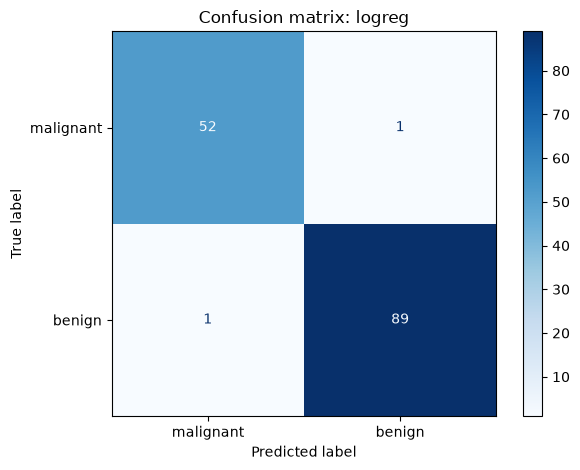

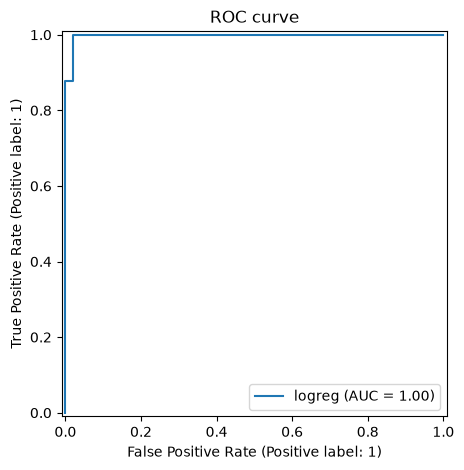

🏃 View run cmp_logreg at: http://localhost:5000/#/experiments/3/runs/2838e15240f44e90aaffcc0c0c915b08
🧪 View experiment at: http://localhost:5000/#/experiments/3
Графики добавлены в запуск: http://localhost:5000/#/experiments/3/runs/2838e15240f44e90aaffcc0c0c915b08


In [35]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

best_model = mlflow.sklearn.load_model(best_model_uri)

predictions = best_model.predict(Xc_test)
probabilities = best_model.predict_proba(Xc_test)[:, 1]

with mlflow.start_run(run_id=best_run_id):
    # Матрица ошибок.
    cm = ConfusionMatrixDisplay.from_predictions(
        yc_test,
        predictions,
        labels=[0, 1],
        display_labels=load_breast_cancer().target_names,
        cmap="Blues",
    )
    cm.ax_.set_title(f"Confusion matrix: {best_model_type}")
    cm.figure_.tight_layout()

    mlflow.log_figure(cm.figure_, "confusion_matrix.png")
    plt.show()
    plt.close(cm.figure_)

    # ROC-кривая.
    roc = RocCurveDisplay.from_predictions(
        yc_test,
        probabilities,
        name=best_model_type,
    )
    roc.ax_.set_title("ROC curve")
    roc.figure_.tight_layout()

    mlflow.log_figure(roc.figure_, "roc_curve.png")
    plt.show()
    plt.close(roc.figure_)

print(
    "Графики добавлены в запуск:",
    f"{UI}/#/experiments/{cancer_exp.experiment_id}/runs/{best_run_id}",
)

### Задача 4. Кривая обучения
Обучите `SGDClassifier(loss="log_loss", random_state=42)` на Breast Cancer 40 эпохами (`partial_fit`)
и после каждой эпохи записывайте `train_accuracy` и `val_accuracy` со `step=epoch`.
Потом через `get_metric_history` найдите эпоху с лучшим `val_accuracy`. Посмотрите график в интерфейсе.

In [36]:
import numpy as np
from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(Xc_train)

Xc_train_scaled = scaler.transform(Xc_train)
Xc_test_scaled = scaler.transform(Xc_test)
classes = np.unique(yc_train)

sgd = SGDClassifier(
    loss="log_loss",
    random_state=42,
)

mlflow.set_experiment(CANCER_EXP)

with mlflow.start_run(run_name="sgd_40_epochs") as run:
    sgd_run_id = run.info.run_id

    mlflow.log_params({
        "model": "SGDClassifier",
        "loss": "log_loss",
        "random_state": 42,
        "epochs": 40,
    })

    for epoch in range(40):
        sgd.partial_fit(
            Xc_train_scaled,
            yc_train,
            classes=classes,
        )

        mlflow.log_metrics(
            {
                "train_accuracy": sgd.score(
                    Xc_train_scaled, yc_train
                ),
                "val_accuracy": sgd.score(
                    Xc_test_scaled, yc_test
                ),
            },
            step=epoch,
        )

# Получаем историю именно из MLflow.
client = mlflow.MlflowClient()

history = client.get_metric_history(
    sgd_run_id,
    "val_accuracy",
)

# При одинаковой accuracy выбираем самую раннюю эпоху.
best_epoch = max(
    history,
    key=lambda metric: (metric.value, -metric.step),
)

print("Количество записанных значений:", len(history))
print("Лучший step:", best_epoch.step)
print("Номер эпохи при счёте с 1:", best_epoch.step + 1)
print(f"Лучший val_accuracy: {best_epoch.value:.6f}")

print(
    "Открыть кривую обучения:",
    f"{UI}/#/experiments/{cancer_exp.experiment_id}/runs/{sgd_run_id}",
)

🏃 View run sgd_40_epochs at: http://localhost:5000/#/experiments/3/runs/2363c9712db1499d8b0add3ccfe95689
🧪 View experiment at: http://localhost:5000/#/experiments/3
Количество записанных значений: 40
Лучший step: 16
Номер эпохи при счёте с 1: 17
Лучший val_accuracy: 0.986014
Открыть кривую обучения: http://localhost:5000/#/experiments/3/runs/2363c9712db1499d8b0add3ccfe95689


### Задача 5. Реестр
Зарегистрируйте лучшую модель из задачи 2 как `f"{MLFLOW_USER}_cancer_model"`, поставьте ей метку `champion`,
загрузите по адресу `models:/…@champion` и сделайте прогноз для первых 5 строк теста.

In [37]:
import pandas as pd

client = mlflow.MlflowClient()
MODEL_NAME = f"{MLFLOW_USER}_cancer_model"

version = mlflow.register_model(
    model_uri=best_model_uri,
    name=MODEL_NAME,
)

client.set_registered_model_alias(
    MODEL_NAME,
    "champion",
    version.version,
)

champion = mlflow.sklearn.load_model(
    f"models:/{MODEL_NAME}@champion"
)

predictions = champion.predict(Xc_test.head(5))

display(pd.DataFrame({
    "actual": yc_test.head(5).to_numpy(),
    "predicted": predictions,
}, index=Xc_test.head(5).index))

print("Название модели:", MODEL_NAME)
print("Зарегистрированная версия:", version.version)
print("Метка: champion")

Successfully registered model 'user1_cancer_model'.
2026/10/08 19:52:07 WARNING mlflow.tracking._model_registry.fluent: Run with id 2838e15240f44e90aaffcc0c0c915b08 has no artifacts at artifact path 'model', registering model based on models:/m-9d335a69129b460aa70b99cc360f0d50 instead
2026/10/08 19:52:07 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: user1_cancer_model, version 1
Created version '1' of model 'user1_cancer_model'.


,actual,predicted
519,1,1
408,0,0
291,1,1
518,1,1
385,0,0


Название модели: user1_cancer_model
Зарегистрированная версия: 1
Метка: champion


### Задача 6 ★. Ворота качества
Обучите новую модель — `RandomForestClassifier(n_estimators=500, max_depth=5, random_state=42)`.
Узнайте `roc_auc` текущего чемпиона (метка → версия → запуск → метрика) и сравните.
Зарегистрируйте новую модель и переставьте `champion` на неё **только если она лучше**.
Напечатайте, кто в итоге чемпион. Так работает автоматический выпуск моделей в конвейере Airflow.

In [38]:
from sklearn.ensemble import RandomForestClassifier

# Находим версию текущего чемпиона.
current_version = client.get_model_version_by_alias(
    MODEL_NAME,
    "champion",
)

# Получаем запуск, из которого зарегистрировали эту версию.
current_run = client.get_run(current_version.run_id)
champion_auc = current_run.data.metrics["roc_auc"]

print("Текущий champion: версия", current_version.version)
print(f"Его ROC-AUC: {champion_auc:.6f}")

# Создаём новую модель.
candidate = make_pipeline(
    StandardScaler(),
    RandomForestClassifier(
        n_estimators=500,
        max_depth=5,
        random_state=42,
    ),
)

mlflow.set_experiment(CANCER_EXP)

with mlflow.start_run(run_name="candidate_rf_500_depth5"):
    mlflow.set_tag("model_type", "random_forest")

    mlflow.log_params({
        "n_estimators": 500,
        "max_depth": 5,
        "random_state": 42,
    })

    candidate.fit(Xc_train, yc_train)

    candidate_auc = roc_auc_score(
        yc_test,
        candidate.predict_proba(Xc_test)[:, 1],
    )

    mlflow.log_metrics({
        "roc_auc": candidate_auc,
        "previous_champion_roc_auc": champion_auc,
    })

    candidate_info = log_sklearn_model(candidate, Xc_test)

    improved = candidate_auc > champion_auc
    mlflow.set_tag(
        "quality_gate_passed",
        str(improved).lower(),
    )

print(f"\nROC-AUC кандидата: {candidate_auc:.6f}")
print(f"Разница с чемпионом: {candidate_auc - champion_auc:+.6f}")

if improved:
    new_version = mlflow.register_model(
        model_uri=candidate_info.model_uri,
        name=MODEL_NAME,
    )

    client.set_registered_model_alias(
        MODEL_NAME,
        "champion",
        new_version.version,
    )

    print("Кандидат лучше: зарегистрирован и назначен чемпионом.")
else:
    print("Улучшения нет: чемпион остаётся прежним.")
    print("Кандидат сохранён в запуске, но не зарегистрирован в реестре.")

# Проверяем фактического чемпиона после сравнения.
final_version = client.get_model_version_by_alias(
    MODEL_NAME,
    "champion",
)
final_run = client.get_run(final_version.run_id)

print("\nИтоговый чемпион:")
print("Название модели:", MODEL_NAME)
print("Версия:", final_version.version)
print("Запуск:", final_run.data.tags.get("mlflow.runName"))
print(f"ROC-AUC: {final_run.data.metrics['roc_auc']:.6f}")

Текущий champion: версия 1
Его ROC-AUC: 0.997694
🏃 View run candidate_rf_500_depth5 at: http://localhost:5000/#/experiments/3/runs/a04efbe12c1d4aacb1f12630568af43c
🧪 View experiment at: http://localhost:5000/#/experiments/3

ROC-AUC кандидата: 0.993291
Разница с чемпионом: -0.004403
Улучшения нет: чемпион остаётся прежним.
Кандидат сохранён в запуске, но не зарегистрирован в реестре.

Итоговый чемпион:
Название модели: user1_cancer_model
Версия: 1
Запуск: cmp_logreg
ROC-AUC: 0.997694


### Задача 7. Три модели параллельно под одним родителем
Сделайте родительский запуск `parallel_cancer` в `CANCER_EXP`. Внутри него **параллельно** (3 потока)
обучите три дочерние модели: логистическую регрессию, `RandomForestClassifier(random_state=42)`
и `KNeighborsClassifier()` (со стандартизацией). В каждой запишите `roc_auc`.
В родителя запишите `best_model` и `best_roc_auc`. Проверьте в интерфейсе, что под родителем три дочерних запуска.

In [39]:
from concurrent.futures import ThreadPoolExecutor

import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import roc_auc_score

mlflow.set_experiment(CANCER_EXP)


def train_child(name, estimator, parent_id):
    # У каждого потока свой клиент и явный идентификатор запуска.
    thread_client = mlflow.MlflowClient()

    child = thread_client.create_run(
        experiment_id=cancer_exp.experiment_id,
        tags={
            "mlflow.runName": f"parallel_{name}",
            "mlflow.parentRunId": parent_id,
            "model_type": name,
        },
    )
    child_id = child.info.run_id

    try:
        model = make_pipeline(
            StandardScaler(),
            estimator,
        )
        model.fit(Xc_train, yc_train)

        score = roc_auc_score(
            yc_test,
            model.predict_proba(Xc_test)[:, 1],
        )

        thread_client.log_metric(
            child_id,
            "roc_auc",
            float(score),
        )
        thread_client.set_terminated(
            child_id,
            status="FINISHED",
        )

        return {
            "model": name,
            "roc_auc": float(score),
            "run_id": child_id,
        }

    except Exception:
        thread_client.set_terminated(
            child_id,
            status="FAILED",
        )
        raise


estimators = {
    "logreg": LogisticRegression(max_iter=5000),
    "random_forest": RandomForestClassifier(random_state=42),
    "knn": KNeighborsClassifier(),
}

with mlflow.start_run(run_name="parallel_cancer") as parent:
    parent_id = parent.info.run_id
    mlflow.log_param("dataset", "breast_cancer")

    with ThreadPoolExecutor(max_workers=3) as pool:
        futures = [
            pool.submit(train_child, name, estimator, parent_id)
            for name, estimator in estimators.items()
        ]
        parallel_results = [
            future.result()
            for future in futures
        ]

    winner = max(
        parallel_results,
        key=lambda result: result["roc_auc"],
    )

    mlflow.log_param("best_model", winner["model"])
    mlflow.log_metric("best_roc_auc", winner["roc_auc"])

display(
    pd.DataFrame(parallel_results)
    .sort_values("roc_auc", ascending=False)
    .reset_index(drop=True)
)

# Проверяем связь дочерних запусков с родителем.
children = mlflow.search_runs(
    experiment_ids=[cancer_exp.experiment_id],
    filter_string=f"tags.mlflow.parentRunId = '{parent_id}'",
)

assert len(children) == 3
assert children["status"].eq("FINISHED").all()

print("Три дочерних запуска успешно завершены.")
print("Лучшая модель:", winner["model"])
print(f"Лучший ROC-AUC: {winner['roc_auc']:.6f}")

print(
    "Родительский запуск:",
    f"{UI}/#/experiments/{cancer_exp.experiment_id}/runs/{parent_id}",
)

🏃 View run parallel_logreg at: http://localhost:5000/#/experiments/3/runs/a2bea5efefe4405388945df694914ad7
🧪 View experiment at: http://localhost:5000/#/experiments/3
🏃 View run parallel_knn at: http://localhost:5000/#/experiments/3/runs/4773f8b733e1428c87b82a2bddccc7e1
🧪 View experiment at: http://localhost:5000/#/experiments/3
🏃 View run parallel_random_forest at: http://localhost:5000/#/experiments/3/runs/3072d9a13aa04705b1e2976f257b9675
🧪 View experiment at: http://localhost:5000/#/experiments/3
🏃 View run parallel_cancer at: http://localhost:5000/#/experiments/3/runs/a66feb9b79434d2bb3bd9f9c3b3b4ebe
🧪 View experiment at: http://localhost:5000/#/experiments/3


,model,roc_auc,run_id
0,logreg,0.997694,a2bea5efefe4405388945df694914ad7
1,random_forest,0.995073,3072d9a13aa04705b1e2976f257b9675
2,knn,0.984486,4773f8b733e1428c87b82a2bddccc7e1


Три дочерних запуска успешно завершены.
Лучшая модель: logreg
Лучший ROC-AUC: 0.997694
Родительский запуск: http://localhost:5000/#/experiments/3/runs/a66feb9b79434d2bb3bd9f9c3b3b4ebe


### Задача 8. Интерфейс
Откройте **http://10.162.1.86:5000**, эксперимент `…_cancer`:
1. отметьте запуски `cmp_*` и нажмите **Compare** — какая модель лучше и насколько?
2. откройте запуск `sgd_40_epochs` → вкладка **Model metrics**: где начинается переобучение?
4. откройте **Models** → свою модель: сколько версий и у какой метка `champion`?

1. На тестовой выборке получены следующие значения ROC-AUC:
    
    LogisticRegression — 0.99769392;

    RandomForestClassifier — 0.99507338;

    KNeighborsClassifier — 0.98448637.

    Лучший результат показала логистическая регрессия. Она превосходит случайный лес на 0.00262054, а метод ближайших соседей — на 0.01320755 по ROC-AUC.

2. На протяжении 40 эпох train_accuracy в целом увеличивается, а val_accuracy колеблется без устойчивого снижения. Явных признаков устойчивого переобучения по этим графикам не обнаружено; однозначно определить эпоху его начала нельзя.

3. В user1_cancer_model зарегистрирована одна версия — Version 1. Ей присвоена метка champion.

---
**Готово?** Следующий шаг — Airflow: тот же код запускается сам, по расписанию, и каждая задача DAG-а
пишет свой запуск в MLflow.